# Which hospitals are most likely to be bottom performers on maternal morbidity?

CMS publishes a Maternal Health file for every Medicare-certified hospital in the US. One of the
measures in it, PC_07a, is the risk adjusted rate of severe obstetric complications, and CMS labels
each hospital as a Top, Middle or Bottom Performer on it.

The problem is that this label only exists for hospitals with enough delivery volume to be scored.
Almost half of the hospitals in the file, 2,295 out of 4,655, have no label at all. So the question I
want to answer is:

**can we predict that a hospital is a Bottom Performer using only information that does not come from
the complication measure itself?**

If that works even partially, it gives a cheap way to flag hospitals worth a closer look, including
the ones CMS cannot score.

I follow CRISP-DM: business understanding, data understanding, data preparation, modeling,
evaluation, and a short deployment example at the end.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.5


## 1. Business understanding

Three questions guide the whole notebook:

1. What does a hospital with poor maternal outcomes look like? Is it the big ones, the small ones,
   the ones doing a lot of C-sections?
2. Does the self reported maternal safety structural measure (SM_7) say anything about actual
   outcomes?
3. Can a model flag likely Bottom Performers well enough to be useful as a screening tool?

The target is binary: Bottom Performer vs everyone else. I picked binary over the three class version
because the practical use case is a watch list, and precision and recall are much easier to explain
on a single class.

## 2. Data understanding

The file is in long format. Each row is one hospital and one measure, so a single hospital shows up
several times.

In [2]:
raw = pd.read_csv("data/Maternal_Health-Hospital.csv", dtype=str)
print("rows, columns:", raw.shape)
print("unique hospitals:", raw["Facility ID"].nunique())
raw.head()

rows, columns: (17945, 16)
unique hospitals: 4655


,Facility ID,Facility Name,Address,City/Town,State,ZIP Code,County/Parish,Telephone Number,Measure ID,Measure Name,Category,Score,Sample,Footnote,Start Date,End Date
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,PC_02,Cesarean Birth,Not Applicable,27,354,NaN,01/01/2025,12/31/2025
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,PC_07a,Risk Adjusted Severe Obstetric Complications (...,Middle Performer,268,1221,NaN,01/01/2025,12/31/2025
2,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,PC_07b,Risk Adjusted Severe Obstetric Complications (...,Middle Performer,67,1221,NaN,01/01/2025,12/31/2025
3,010001,SOUTHEAST HEALTH MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,HOUSTON,(334) 793-8701,SM_7,Maternal Morbidity Structural Measure,Not Applicable,Yes,Not Applicable,NaN,01/01/2025,12/31/2025
4,010005,MARSHALL MEDICAL CENTERS,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,MARSHALL,(256) 593-8310,PC_02,Cesarean Birth,Not Applicable,20,396,NaN,01/01/2025,12/31/2025


In [3]:
# what measures are in the file, and which of them carry a performance label
pd.crosstab(raw["Measure ID"] + " - " + raw["Measure Name"].str.slice(0, 45), raw["Category"])

Category,Bottom Performer,Middle Performer,Not Applicable,Not Available,Top Performer
row_0,,,,,
PC_02 - Cesarean Birth,0,0,4430,0,0
PC_07a - Risk Adjusted Severe Obstetric Complications,592,1177,0,2070,591
PC_07b - Risk Adjusted Severe Obstetric Complications,596,1174,0,2070,590
SM_7 - Maternal Morbidity Structural Measure,0,0,4655,0,0


Four measures:

| Measure | What it is | Labelled? |
| --- | --- | --- |
| PC_02 | Cesarean birth rate for low risk first births (NTSV), in % | no |
| PC_07a | Risk adjusted severe obstetric complications, all cases, per 10,000 | yes |
| PC_07b | Same but excluding blood-transfusion-only cases | yes |
| SM_7 | Maternal Morbidity Structural Measure, a Yes/No attestation | no |

Only PC_07a and PC_07b get a Top/Middle/Bottom label. Everything else is "Not Applicable".

In [4]:
# the Score and Sample columns are text because CMS uses words for missing data
for col in ["Score", "Sample", "Footnote"]:
    print("---", col, "---")
    print(raw[col].value_counts(dropna=False).head(5).to_string(), "\n")

--- Score ---
Score
Not Available                                                                   7406
Yes                                                                             2242
Not Applicable (our hospital does not provide inpatient labor/delivery care)    1342
25                                                                               153
28                                                                               151 

--- Sample ---
Sample
Not Available     6388
Not Applicable    4655
75                  21
94                  20
90                  19 

--- Footnote ---
Footnote
NaN    10539
5       6439
7        522
1        271
19       172 



So missing values are not blank, they are the strings `Not Available` and `Not Applicable`. The
`Footnote` column explains why: code 5 is "results are not available for this reporting period" and
code 1 is "the number of cases is too small to report". That is the main cleaning job.

Next I reshape the file so one row equals one hospital.

In [5]:
MISSING_TOKENS = ["Not Available", "Not Applicable"]

def to_number(s):
    # CMS writes missing values as words, so turn those into NaN and the rest into floats
    return pd.to_numeric(s.where(~s.isin(MISSING_TOKENS)), errors="coerce")

meta = (raw[["Facility ID", "Facility Name", "City/Town", "State", "County/Parish"]]
        .drop_duplicates("Facility ID")
        .set_index("Facility ID"))

score = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Score", aggfunc="first")
sample = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Sample", aggfunc="first")
label = raw.pivot_table(index="Facility ID", columns="Measure ID", values="Category", aggfunc="first")

hosp = meta.copy()
hosp["cesarean_rate"] = to_number(score["PC_02"])      # % of low risk first births by c-section
hosp["ntsv_births"]   = to_number(sample["PC_02"])     # denominator of PC_02
hosp["deliveries"]    = to_number(sample["PC_07a"])    # denominator of PC_07a, total scored births
hosp["smm_rate"]      = to_number(score["PC_07a"])     # complications per 10,000
hosp["smm_rate_nobt"] = to_number(score["PC_07b"])
hosp["sm7_raw"]       = score["SM_7"]
hosp["tier"]          = label["PC_07a"].where(~label["PC_07a"].isin(MISSING_TOKENS))

print("hospital level shape:", hosp.shape)
hosp.head()

hospital level shape: (4655, 11)


,Facility Name,City/Town,State,County/Parish,cesarean_rate,ntsv_births,deliveries,smm_rate,smm_rate_nobt,sm7_raw,tier
Facility ID,,,,,,,,,,,
010001,SOUTHEAST HEALTH MEDICAL CENTER,DOTHAN,AL,HOUSTON,27.0,354.0,1221.0,268.0,67.0,Yes,Middle Performer
010005,MARSHALL MEDICAL CENTERS,BOAZ,AL,MARSHALL,20.0,396.0,1526.0,500.0,42.0,Yes,Bottom Performer
010006,NORTH ALABAMA MEDICAL CENTER,FLORENCE,AL,LAUDERDALE,23.0,377.0,1150.0,58.0,55.0,Yes,Top Performer
010007,MIZELL MEMORIAL HOSPITAL,OPP,AL,COVINGTON,NaN,NaN,NaN,NaN,NaN,Not Applicable (our hospital does not provide ...,NaN
010011,ST. VINCENT'S EAST,BIRMINGHAM,AL,JEFFERSON,NaN,NaN,NaN,NaN,NaN,Not Applicable (our hospital does not provide ...,NaN


In [6]:
print("missing values per column\n")
print(hosp.isna().sum().to_string())
print("\nhospitals with a performance tier:", hosp["tier"].notna().sum(),
      f"({hosp['tier'].notna().mean():.1%})")
print()
print(hosp["tier"].value_counts(dropna=False).to_string())

missing values per column

Facility Name       0
City/Town           0
State               0
County/Parish       0
cesarean_rate    2473
ntsv_births      2473
deliveries       2295
smm_rate         2295
smm_rate_nobt    2295
sm7_raw             0
tier             2295

hospitals with a performance tier: 2360 (50.7%)

tier
NaN                 2295
Middle Performer    1177
Bottom Performer     592
Top Performer        591


2,295 of 4,655 hospitals have no tier. Looking at SM_7 explains most of it: a large group answered
"our hospital does not provide inpatient labor/delivery care", so there is nothing to score.

In [7]:
hosp["sm7_raw"].value_counts(dropna=False)

sm7_raw
Yes                                                                             2242
Not Applicable (our hospital does not provide inpatient labor/delivery care)    1342
Not Available                                                                   1018
No                                                                                53
Name: count, dtype: int64

### Distributions

Before building anything I want to see the shape of the numeric columns.

In [8]:
num_cols = ["cesarean_rate", "deliveries", "smm_rate", "smm_rate_nobt"]
print(hosp[num_cols].describe().round(2).to_string())
print("\nskewness")
print(hosp[num_cols].skew().round(2).to_string())

       cesarean_rate  deliveries  smm_rate  smm_rate_nobt
count        2182.00     2360.00   2360.00        2360.00
mean           25.78     1371.89    333.12          74.62
std             9.67     1607.83    207.68          80.47
min             0.00       25.00     31.00          21.00
25%            21.00      330.00    207.00          53.75
50%            25.00      826.50    308.00          64.00
75%            29.00     1875.50    420.00          83.00
max           100.00    22616.00   4531.00        3548.00

skewness
cesarean_rate     3.48
deliveries        3.41
smm_rate          5.14
smm_rate_nobt    34.75


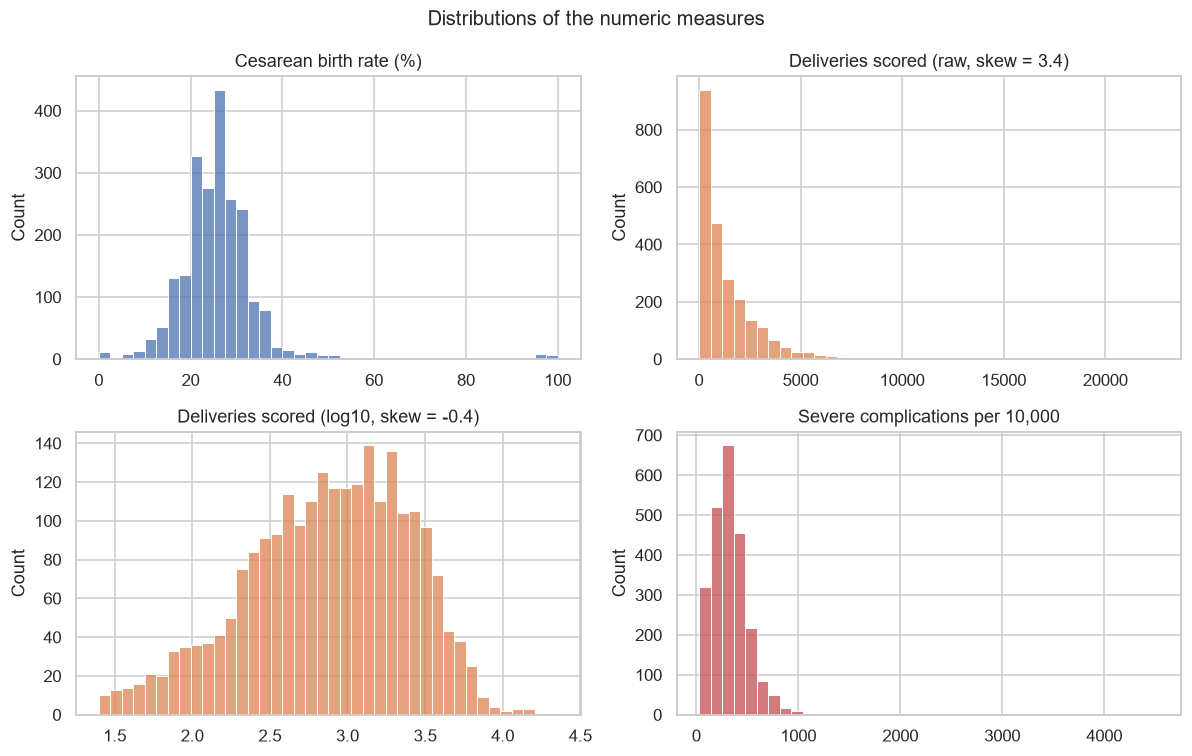

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
ax = ax.ravel()

sns.histplot(hosp["cesarean_rate"].dropna(), bins=40, ax=ax[0], color="#4C72B0")
ax[0].set_title("Cesarean birth rate (%)")
ax[0].set_xlabel("")

sns.histplot(hosp["deliveries"].dropna(), bins=40, ax=ax[1], color="#DD8452")
ax[1].set_title("Deliveries scored (raw, skew = %.1f)" % hosp["deliveries"].skew())
ax[1].set_xlabel("")

sns.histplot(np.log10(hosp["deliveries"].dropna()), bins=40, ax=ax[2], color="#DD8452")
ax[2].set_title("Deliveries scored (log10, skew = %.1f)" % np.log10(hosp["deliveries"].dropna()).skew())
ax[2].set_xlabel("")

sns.histplot(hosp["smm_rate"].dropna(), bins=40, ax=ax[3], color="#C44E52")
ax[3].set_title("Severe complications per 10,000")
ax[3].set_xlabel("")

fig.suptitle("Distributions of the numeric measures", fontsize=13)
fig.tight_layout()
fig.savefig("images/fig1_distributions.png", bbox_inches="tight")
plt.show()

The cesarean rate is roughly bell shaped around 25% with a long right tail and a few hospitals at
0% and 100% (very small denominators). Delivery volume is heavily right skewed, skew above 3, which
is normal for hospital size. A log10 transform fixes it almost perfectly, so that is what I will
feed the model.

### The target, and a leakage trap

The tier label is a threshold applied to `smm_rate`. So `smm_rate` and the label are the same thing,
and `smm_rate_nobt` is the same measure with a slightly different definition. Using either as a
feature would give a near perfect model that is completely useless, because in real life you only
know those numbers after CMS has already scored and labelled the hospital.

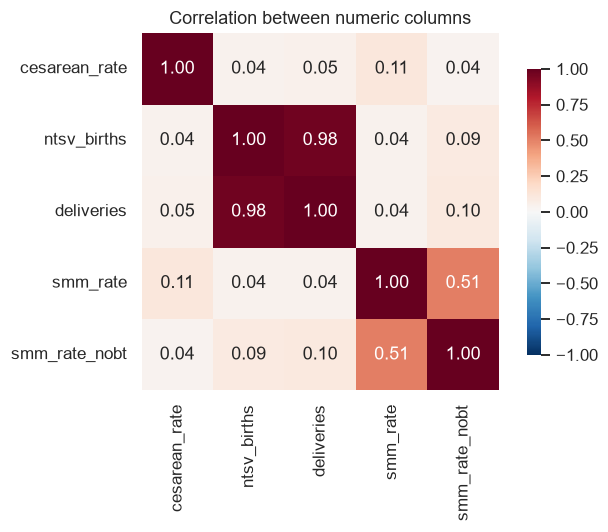

smm_rate vs the label it produces:
                   count    min   mean     max
tier                                          
Bottom Performer   592.0  420.0  578.0  4531.0
Middle Performer  1177.0  208.0  310.6   419.0
Top Performer      591.0   31.0  132.7   207.0


In [10]:
corr = hosp[["cesarean_rate", "ntsv_births", "deliveries", "smm_rate", "smm_rate_nobt"]].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation between numeric columns")
fig.tight_layout()
fig.savefig("images/fig2_correlation.png", bbox_inches="tight")
plt.show()

print("smm_rate vs the label it produces:")
print(hosp.groupby("tier")["smm_rate"].describe()[["count", "min", "mean", "max"]].round(1).to_string())

The ranges do not overlap at all: every Bottom Performer is at 420 or above, every Top Performer is
at 207 or below. That confirms the label is just a cut on the score. Both `smm_rate` and
`smm_rate_nobt` are dropped from the feature set.

Also note `ntsv_births` and `deliveries` correlate at 0.98, they measure the same thing (size), so I
keep only `deliveries`.

hospitals used for modelling: 2360
bottom performers: 592 (25.1%)


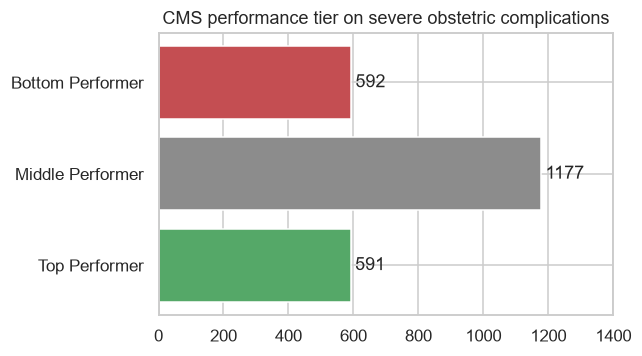

In [11]:
labelled = hosp[hosp["tier"].notna()].copy()
labelled["is_bottom"] = (labelled["tier"] == "Bottom Performer").astype(int)

print("hospitals used for modelling:", len(labelled))
print("bottom performers: %d (%.1f%%)" % (labelled["is_bottom"].sum(), 100 * labelled["is_bottom"].mean()))

fig, ax = plt.subplots(figsize=(6, 3.4))
order = ["Top Performer", "Middle Performer", "Bottom Performer"]
counts = labelled["tier"].value_counts().reindex(order)
bars = ax.barh(order, counts.values, color=["#55A868", "#8C8C8C", "#C44E52"])
ax.bar_label(bars, padding=3)
ax.set_xlim(0, 1400)
ax.set_title("CMS performance tier on severe obstetric complications")
fig.tight_layout()
fig.savefig("images/fig3_target_balance.png", bbox_inches="tight")
plt.show()

25% of the labelled hospitals are Bottom Performers. That matters for evaluation: a model that always
says "not bottom" is already 75% accurate while catching nobody. Accuracy on its own will be
misleading here.

### What relates to being a Bottom Performer?

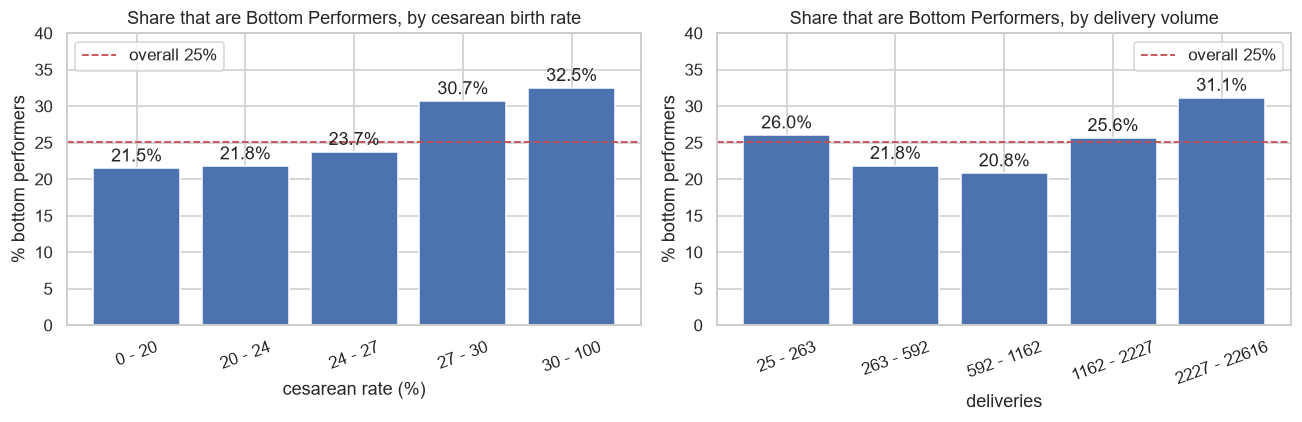

                    mean  size
cesarean rate (%)             
0 - 20             0.215   475
20 - 24            0.218   510
24 - 27            0.237   434
27 - 30            0.307   365
30 - 100           0.325   397 

               mean  size
deliveries               
25 - 263      0.260   473
263 - 592     0.218   472
592 - 1162    0.208   471
1162 - 2227   0.256   472
2227 - 22616  0.311   472


In [12]:
def bottom_rate_by_bin(series, bins=5, label=""):
    q = pd.qcut(series, bins, duplicates="drop")
    g = labelled.groupby(q, observed=True)["is_bottom"].agg(["mean", "size"])
    g.index = [f"{max(iv.left, 0):.0f} - {iv.right:.0f}" for iv in g.index]
    g.index.name = label
    return g

ces = bottom_rate_by_bin(labelled["cesarean_rate"], 5, "cesarean rate (%)")
vol = bottom_rate_by_bin(labelled["deliveries"], 5, "deliveries")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axis, g, title in [(ax[0], ces, "by cesarean birth rate"), (ax[1], vol, "by delivery volume")]:
    bars = axis.bar(g.index, 100 * g["mean"], color="#4C72B0")
    axis.bar_label(bars, fmt="%.1f%%", padding=2)
    axis.axhline(100 * labelled["is_bottom"].mean(), color="#C44E52", ls="--", lw=1.2,
                 label="overall 25%")
    axis.set_title("Share that are Bottom Performers, " + title)
    axis.set_ylabel("% bottom performers")
    axis.set_xlabel(g.index.name)
    axis.set_ylim(0, 40)
    axis.tick_params(axis="x", rotation=20)
    axis.legend()
fig.tight_layout()
fig.savefig("images/fig4_rate_by_bin.png", bbox_inches="tight")
plt.show()

print(ces.round(3).to_string(), "\n")
print(vol.round(3).to_string())

Cesarean rate moves in one direction: the lowest quintile has 21.5% bottom performers, the highest
32.5%. Volume is more of a U shape, the very largest hospitals are the worst group, which makes sense
since they take the complicated referrals.

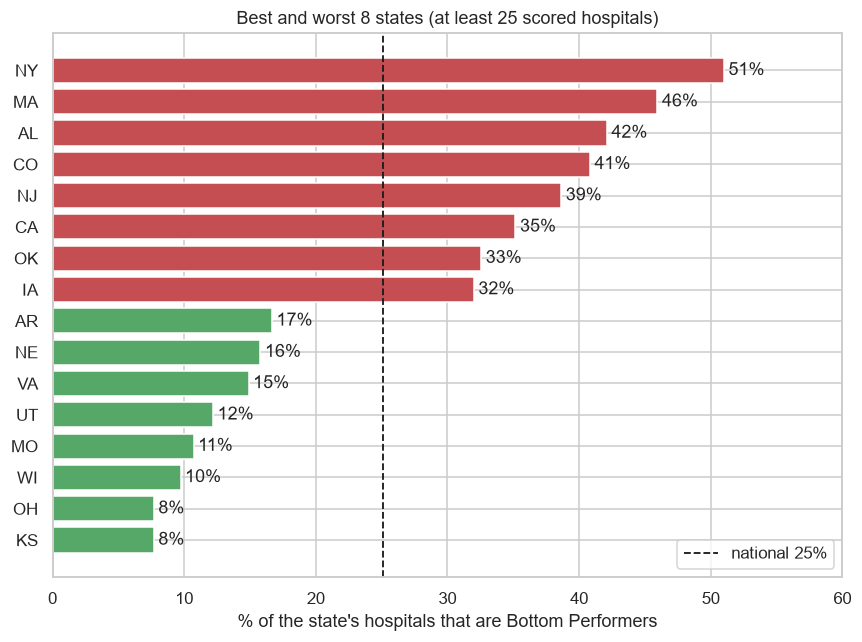

spread across states: 8% to 51%


In [13]:
state = (labelled.groupby("State")["is_bottom"].agg(["mean", "size"])
         .query("size >= 25").sort_values("mean"))
ends = pd.concat([state.head(8), state.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#55A868"] * 8 + ["#C44E52"] * 8
bars = ax.barh(ends.index, 100 * ends["mean"], color=colors)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.axvline(100 * labelled["is_bottom"].mean(), color="k", ls="--", lw=1.2, label="national 25%")
ax.set_xlabel("% of the state's hospitals that are Bottom Performers")
ax.set_title("Best and worst 8 states (at least 25 scored hospitals)")
ax.set_xlim(0, 60)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/fig5_states.png", bbox_inches="tight")
plt.show()

print("spread across states: %.0f%% to %.0f%%" % (100 * state["mean"].min(), 100 * state["mean"].max()))

This is the biggest single pattern in the data. Ohio and Kansas sit around 8%, New York is at 51%.
A difference of more than six times between states is far larger than anything the hospital level
columns show, so geography has to be in the model.

Now the structural measure.

In [14]:
labelled["sm7_adopted"] = (labelled["sm7_raw"] == "Yes").astype(int)
sm7 = labelled.groupby("sm7_adopted")["is_bottom"].agg(["mean", "size"])
sm7.index = ["did not attest", "attested Yes"]
print(sm7.round(3).to_string())

                 mean  size
did not attest  0.247   186
attested Yes    0.251  2174


Basically identical, 24.7% against 25.1%. Saying yes to the maternal safety structural measure tells
you nothing about the hospital's actual complication rate. That answers question 2, and it is a
negative result worth reporting.

One thing that does show up is academic hospitals. The facility name is the only clue the file gives
about hospital type, so I check for university affiliation in the name.

In [15]:
name = labelled["Facility Name"].str.upper()
labelled["is_academic"] = name.str.contains(r"UNIV|COLLEGE|SCHOOL OF MED", regex=True, na=False).astype(int)
labelled["is_faith_based"] = name.str.contains(r"\bST\b|SAINT|MERCY|PROVIDENCE|SACRED|MARY",
                                               regex=True, na=False).astype(int)

for flag, nice in [("is_academic", "university in the name"), ("is_faith_based", "faith based name")]:
    g = labelled.groupby(flag)["is_bottom"].agg(["mean", "size"])
    g.index = ["no", "yes"]
    print(nice)
    print(g.round(3).to_string(), "\n")

university in the name
      mean  size
no   0.243  2268
yes  0.446    92 

faith based name
      mean  size
no   0.257  2034
yes  0.212   326 



45% of university hospitals are Bottom Performers against 24% for the rest. Only 92 hospitals, so the
estimate is noisy, but the direction is consistent with high risk case mix and it is worth keeping.

## 3. Summary of the exploration, and what needs cleaning

What I found:

- The file is long format and has to be pivoted to one row per hospital.
- Missing data is encoded as text, `Not Available` and `Not Applicable`, not as blanks. This is the
  main cleaning problem, because every numeric column loads as object.
- Delivery volume is strongly right skewed and needs a log transform.
- 2,295 hospitals cannot be labelled, mostly because they do not deliver babies. Those rows cannot be
  used for supervised training, so the model is fit on the 2,360 labelled ones.
- `smm_rate` and `smm_rate_nobt` leak the target and must be dropped.
- `ntsv_births` duplicates `deliveries` at r = 0.98, so one of them goes.
- 179 labelled hospitals have no cesarean rate. That is only 8%, so median imputation inside the
  pipeline is enough, and the imputer is fit on training folds only so nothing leaks.

So yes, the data needs cleaning, and the plan is: cast the text to numbers, pivot, drop the leaking
and duplicated columns, log the volume, add the name based flags, impute the rest.

Because the target is categorical and we have labelled examples, this is a supervised binary
classification problem.

## 4. Data preparation

In [16]:
CENSUS_REGION = {
    "CT": "Northeast", "ME": "Northeast", "MA": "Northeast", "NH": "Northeast", "RI": "Northeast",
    "VT": "Northeast", "NJ": "Northeast", "NY": "Northeast", "PA": "Northeast",
    "IL": "Midwest", "IN": "Midwest", "MI": "Midwest", "OH": "Midwest", "WI": "Midwest",
    "IA": "Midwest", "KS": "Midwest", "MN": "Midwest", "MO": "Midwest", "NE": "Midwest",
    "ND": "Midwest", "SD": "Midwest",
    "DE": "South", "FL": "South", "GA": "South", "MD": "South", "NC": "South", "SC": "South",
    "VA": "South", "DC": "South", "WV": "South", "AL": "South", "KY": "South", "MS": "South",
    "TN": "South", "AR": "South", "LA": "South", "OK": "South", "TX": "South",
    "AZ": "West", "CO": "West", "ID": "West", "MT": "West", "NV": "West", "NM": "West",
    "UT": "West", "WY": "West", "AK": "West", "CA": "West", "HI": "West", "OR": "West", "WA": "West",
    "PR": "Territories", "GU": "Territories", "VI": "Territories", "AS": "Territories",
    "MP": "Territories",
}

model_df = labelled.copy()
model_df["log_deliveries"] = np.log10(model_df["deliveries"])
model_df["region"] = model_df["State"].map(CENSUS_REGION)

# states with very few scored hospitals get pooled so the model does not learn noise
state_counts = model_df["State"].value_counts()
big_states = state_counts[state_counts >= 25].index
model_df["state_grp"] = np.where(model_df["State"].isin(big_states), model_df["State"], "OTHER")

assert model_df["region"].notna().all(), "unmapped state"
print("states kept separately:", len(big_states), "| pooled into OTHER:",
      int((model_df["state_grp"] == "OTHER").sum()))

states kept separately: 34 | pooled into OTHER: 261


In [17]:
NUMERIC = ["cesarean_rate", "log_deliveries"]
BINARY = ["is_academic", "is_faith_based"]
CATEGORICAL = ["state_grp", "region"]
FEATURES = NUMERIC + BINARY + CATEGORICAL

X = model_df[FEATURES]
y = model_df["is_bottom"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print("features:", FEATURES)
print("train:", X_train.shape, "| test:", X_test.shape)
print("bottom rate - train %.3f, test %.3f" % (y_train.mean(), y_test.mean()))

features: ['cesarean_rate', 'log_deliveries', 'is_academic', 'is_faith_based', 'state_grp', 'region']
train: (1770, 6) | test: (590, 6)
bottom rate - train 0.251, test 0.251


In [18]:
# imputing and scaling live inside the pipeline so they are refit on every CV fold
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("bin", "passthrough", BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), CATEGORICAL),
])
preprocess.fit(X_train)
print("columns after encoding:", preprocess.transform(X_train).shape[1])

columns after encoding: 42


## 5. Modeling

I compare four options. The dummy is there to make the 75% accuracy trap obvious. Logistic regression
and random forest use `class_weight="balanced"` so the minority class is not ignored. Gradient
boosting is kept shallow because the dataset is small.

The comparison metric is ROC AUC from 5 fold stratified cross validation, since AUC does not depend
on a threshold and is not fooled by the class imbalance.

In [19]:
models = {
    "Dummy (always 'not bottom')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=8,
                                            class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05,
                                                    max_depth=2, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
fitted = {}

for name, est in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", est)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    rows.append({"model": name, "cv_auc": scores.mean(), "cv_std": scores.std()})

comparison = pd.DataFrame(rows).set_index("model").sort_values("cv_auc", ascending=False)
comparison.round(4)

,cv_auc,cv_std
model,,
Random Forest,0.6239,0.0312
Logistic Regression,0.6160,0.0268
Gradient Boosting,0.5910,0.0523
Dummy (always 'not bottom'),0.5000,0.0000


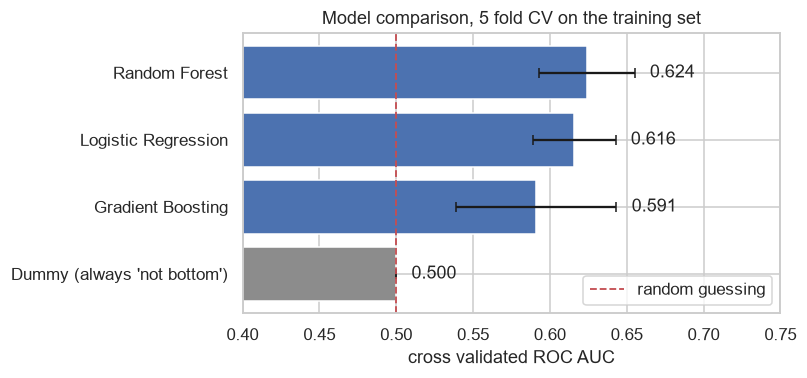

best model: Random Forest


In [20]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
plot_df = comparison.sort_values("cv_auc")
bars = ax.barh(plot_df.index, plot_df["cv_auc"], xerr=plot_df["cv_std"],
               color=["#8C8C8C" if "Dummy" in i else "#4C72B0" for i in plot_df.index],
               capsize=3)
ax.bar_label(bars, fmt="%.3f", padding=10)
ax.axvline(0.5, color="#C44E52", ls="--", lw=1.2, label="random guessing")
ax.set_xlim(0.4, 0.75)
ax.set_xlabel("cross validated ROC AUC")
ax.set_title("Model comparison, 5 fold CV on the training set")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/fig6_model_comparison.png", bbox_inches="tight")
plt.show()

best_name = comparison.index[0]
best_model = fitted[best_name]
print("best model:", best_name)

All three real models land between 0.59 and 0.62 AUC, clearly above the 0.50 of random guessing but
nowhere near strong. The fact that three very different algorithms end up so close together tells me
this is the amount of signal that is actually in these features, not a tuning problem.

I take the best scoring one forward to the held out test set.

## 6. Evaluation

In [21]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(best_name, "on the held out test set\n")
print("accuracy  %.3f" % accuracy_score(y_test, y_pred))
print("precision %.3f" % precision_score(y_test, y_pred, zero_division=0))
print("recall    %.3f" % recall_score(y_test, y_pred, zero_division=0))
print("f1        %.3f" % f1_score(y_test, y_pred, zero_division=0))
print("roc auc   %.3f" % roc_auc_score(y_test, y_proba))
print("avg prec  %.3f" % average_precision_score(y_test, y_proba))
print()
print(classification_report(y_test, y_pred, target_names=["not bottom", "bottom"], digits=3))

Random Forest on the held out test set

accuracy  0.627
precision 0.349
recall    0.561
f1        0.430
roc auc   0.629
avg prec  0.395

              precision    recall  f1-score   support

  not bottom      0.815     0.649     0.723       442
      bottom      0.349     0.561     0.430       148

    accuracy                          0.627       590
   macro avg      0.582     0.605     0.576       590
weighted avg      0.698     0.627     0.649       590



In [22]:
dummy_pred = fitted["Dummy (always 'not bottom')"].predict(X_test)
print("for reference, the dummy model on the same test set")
print("  accuracy %.3f | recall %.3f" % (accuracy_score(y_test, dummy_pred),
                                         recall_score(y_test, dummy_pred, zero_division=0)))

for reference, the dummy model on the same test set
  accuracy 0.749 | recall 0.000


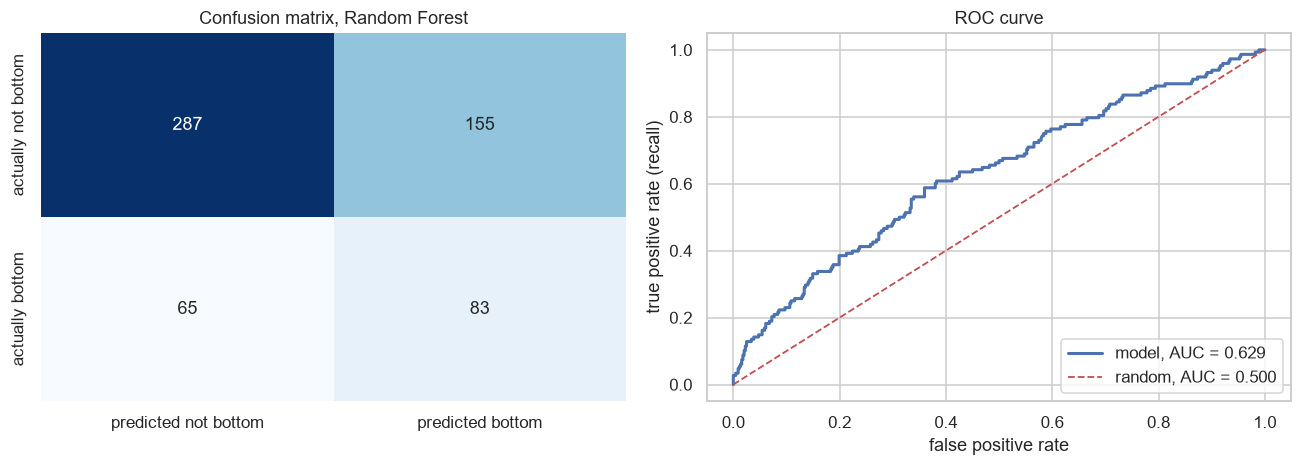

In [23]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["predicted not bottom", "predicted bottom"],
            yticklabels=["actually not bottom", "actually bottom"])
ax[0].set_title("Confusion matrix, %s" % best_name)

fpr, tpr, _ = roc_curve(y_test, y_proba)
ax[1].plot(fpr, tpr, color="#4C72B0", lw=2,
           label="model, AUC = %.3f" % roc_auc_score(y_test, y_proba))
ax[1].plot([0, 1], [0, 1], color="#C44E52", ls="--", lw=1.2, label="random, AUC = 0.500")
ax[1].set_xlabel("false positive rate")
ax[1].set_ylabel("true positive rate (recall)")
ax[1].set_title("ROC curve")
ax[1].legend(loc="lower right")

fig.tight_layout()
fig.savefig("images/fig7_evaluation.png", bbox_inches="tight")
plt.show()

### What these numbers actually mean

- **Accuracy** is the share of hospitals the model gets right in either direction. It looks
  unimpressive next to the dummy's 0.75, and that is the point. The dummy reaches 0.75 by calling
  every hospital safe, so it never finds a single bottom performer. Accuracy rewards that laziness
  and is the wrong headline metric for a 25/75 split.
- **Recall** is the share of real Bottom Performers the model actually flags. For a watch list this is
  the number that matters, because a missed bad hospital is the expensive mistake.
- **Precision** is how often a flag is correct. Here it is only slightly above the 25% base rate, so
  most flagged hospitals turn out to be fine. That is the cost of the high recall.
- **F1** balances the two, useful for comparing threshold choices.
- **ROC AUC** is the probability the model scores a random Bottom Performer higher than a random
  non-bottom one. At roughly 0.63 it ranks correctly about 63% of the time against 50% for a coin
  flip. Real, but weak.

The model is not deciding anything on its own. It is a ranking tool, and the threshold is a policy
choice about how many false alarms you can afford to review.

In [24]:
rows = []
for t in np.arange(0.20, 0.76, 0.05):
    pred_t = (y_proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "flagged": int(pred_t.sum()),
        "accuracy": accuracy_score(y_test, pred_t),
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
    })
sweep = pd.DataFrame(rows).set_index("threshold")
sweep.round(3)

,flagged,accuracy,precision,recall,f1
threshold,,,,,
0.20,586,0.258,0.253,1.000,0.403
0.25,571,0.276,0.256,0.986,0.406
0.30,546,0.302,0.258,0.953,0.406
0.35,477,0.381,0.273,0.878,0.416
0.40,409,0.453,0.286,0.791,0.420
0.45,323,0.537,0.307,0.669,0.420
0.50,238,0.627,0.349,0.561,0.430
0.55,146,0.695,0.390,0.385,0.388
0.60,91,0.724,0.418,0.257,0.318


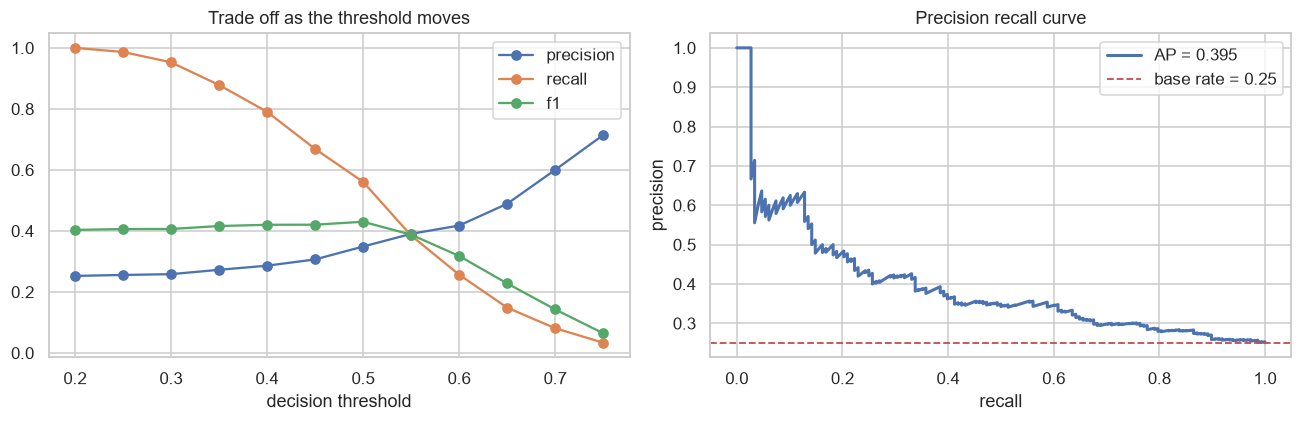

In [25]:
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sweep.index, sweep["precision"], marker="o", label="precision")
ax[0].plot(sweep.index, sweep["recall"], marker="o", label="recall")
ax[0].plot(sweep.index, sweep["f1"], marker="o", label="f1")
ax[0].set_xlabel("decision threshold")
ax[0].set_title("Trade off as the threshold moves")
ax[0].legend()

ax[1].plot(rec, prec, color="#4C72B0", lw=2,
           label="AP = %.3f" % average_precision_score(y_test, y_proba))
ax[1].axhline(y_test.mean(), color="#C44E52", ls="--", lw=1.2,
              label="base rate = %.2f" % y_test.mean())
ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision")
ax[1].set_title("Precision recall curve")
ax[1].legend()

fig.tight_layout()
fig.savefig("images/fig8_threshold.png", bbox_inches="tight")
plt.show()

### Reading the threshold table

The default 0.50 cut is actually the best F1 here, 0.430, flagging 238 of the 590 test hospitals and
catching 56% of the real Bottom Performers. Moving down to 0.45 raises recall to 0.67 but drops
precision to 0.31 and flags 323 hospitals, more than half the list. Below 0.40 the model flags almost
everything, so recall looks great and the output is useless.

Worth being explicit about one thing: both the logistic regression and the random forest use
`class_weight="balanced"`, which deliberately over-weights the minority class. That shifts the
predicted probabilities upward, so a 0.50 output does not mean "50% chance". These values are
**ranking scores**, not calibrated probabilities. They are fine for sorting hospitals, which is what
I want, but they should not be read as literal risk percentages.

### Which features carry the signal

I use permutation importance on the test set instead of the built in importances, because tree
importances are biased towards columns with many categories, and `state_grp` has 35 of them.

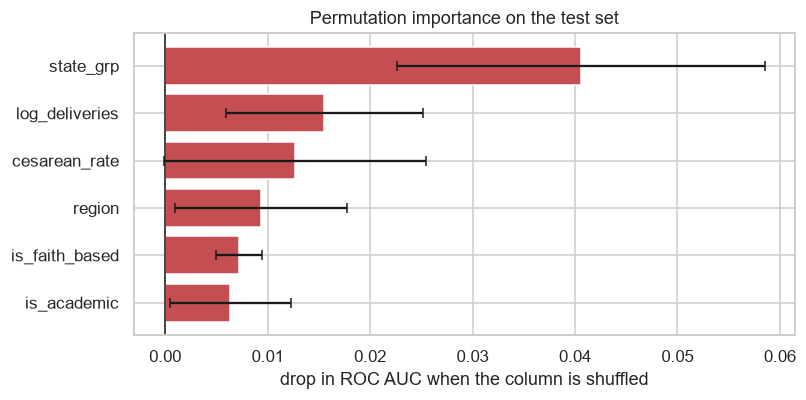

,drop_in_auc,std
feature,,
state_grp,0.0406,0.0179
log_deliveries,0.0155,0.0096
cesarean_rate,0.0126,0.0128
region,0.0093,0.0084
is_faith_based,0.0072,0.0022
is_academic,0.0064,0.0059


In [26]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=1)

importance = (pd.DataFrame({"feature": FEATURES,
                            "drop_in_auc": perm.importances_mean,
                            "std": perm.importances_std})
              .set_index("feature").sort_values("drop_in_auc"))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh(importance.index, importance["drop_in_auc"], xerr=importance["std"],
               color=["#C44E52" if v > 0 else "#8C8C8C" for v in importance["drop_in_auc"]],
               capsize=3)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("drop in ROC AUC when the column is shuffled")
ax.set_title("Permutation importance on the test set")
fig.tight_layout()
fig.savefig("images/fig9_importance.png", bbox_inches="tight")
plt.show()

importance.sort_values("drop_in_auc", ascending=False).round(4)

Geography and size do the work, the cesarean rate adds a little, and the name flags add very little
on their own once the state is known. Nothing here is a strong predictor, which is consistent with
the AUC.

## 7. A new scenario

Suppose a state health department is planning its maternal safety reviews for next year and has
budget to visit a handful of hospitals. Three hospitals are on the shortlist and none of them has a
published CMS tier yet. Which one should the team visit first?

- **Hospital A**: large university hospital in New York, about 3,000 scored deliveries, cesarean rate 31%.
- **Hospital B**: mid size community hospital in Ohio, about 900 deliveries, cesarean rate 22%.
- **Hospital C**: small faith based hospital in Texas, about 250 deliveries, cesarean rate 26%.

In [27]:
scenario = pd.DataFrame([
    {"name": "A - university, New York, 3000 births",
     "cesarean_rate": 31.0, "deliveries": 3000, "is_academic": 1, "is_faith_based": 0,
     "State": "NY"},
    {"name": "B - community, Ohio, 900 births",
     "cesarean_rate": 22.0, "deliveries": 900, "is_academic": 0, "is_faith_based": 0,
     "State": "OH"},
    {"name": "C - small faith based, Texas, 250 births",
     "cesarean_rate": 26.0, "deliveries": 250, "is_academic": 0, "is_faith_based": 1,
     "State": "TX"},
]).set_index("name")

scenario["log_deliveries"] = np.log10(scenario["deliveries"])
scenario["region"] = scenario["State"].map(CENSUS_REGION)
scenario["state_grp"] = np.where(scenario["State"].isin(big_states), scenario["State"], "OTHER")

scenario["risk_score"] = best_model.predict_proba(scenario[FEATURES])[:, 1]

# the model's own median score on the test set is the fair reference point, not the 25% base rate,
# because class_weight="balanced" shifts these scores upward
reference = float(np.median(y_proba))
scenario["above_median"] = np.where(scenario["risk_score"] >= reference, "yes", "no")
scenario["flagged_at_0.50"] = np.where(scenario["risk_score"] >= 0.50, "yes", "no")
print("median risk score across test hospitals: %.3f" % reference)

scenario[["cesarean_rate", "deliveries", "State", "risk_score", "above_median", "flagged_at_0.50"]] \
    .sort_values("risk_score", ascending=False).round(3)

median risk score across test hospitals: 0.467


,cesarean_rate,deliveries,State,risk_score,above_median,flagged_at_0.50
name,,,,,,
"A - university, New York, 3000 births",31.0,3000,NY,0.751,yes,yes
"C - small faith based, Texas, 250 births",26.0,250,TX,0.548,yes,yes
"B - community, Ohio, 900 births",22.0,900,OH,0.299,no,no


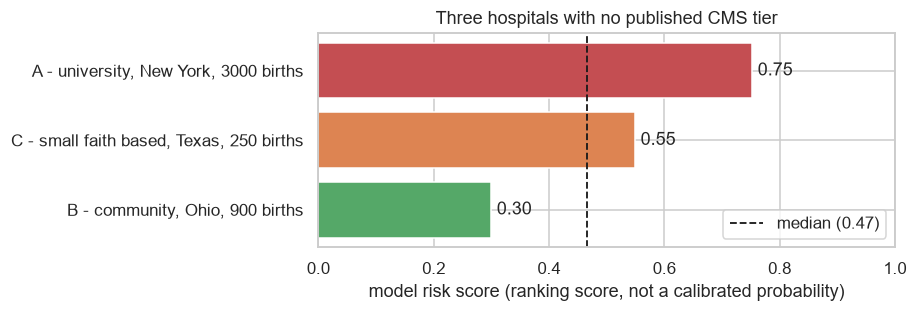

In [28]:
fig, ax = plt.subplots(figsize=(8.5, 3))
s = scenario.sort_values("risk_score")
bars = ax.barh(s.index, s["risk_score"],
               color=["#55A868", "#DD8452", "#C44E52"])
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.axvline(reference, color="k", ls="--", lw=1.2,
           label="median (%.2f)" % reference)
ax.set_xlim(0, 1.0)
ax.set_xlabel("model risk score (ranking score, not a calibrated probability)")
ax.set_title("Three hospitals with no published CMS tier")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/fig10_scenario.png", bbox_inches="tight")
plt.show()

### Reading the prediction

The ranking is clear: Hospital A first, then C, then B. A scores 0.75, C 0.55 and B 0.30, and only A
and C land above the 0.50 cut. So the review team should start with A, and B is the one they can
reasonably skip this year.

The gap between A and B is the useful part. Both are ordinary hospitals on paper, but A is a large
academic centre in the state with the worst published record and a cesarean rate near the top
quintile, while B is a mid size community hospital in one of the best states with a low cesarean
rate. Every signal the model has points the same way for both.

Hospital C is the interesting one. It scores above the cut mostly on size: very small delivery
volumes make the published rate unstable, and small hospitals were slightly worse than mid size ones
in the exploration. That is a statistical artefact as much as a quality signal, and it is a good
example of why this output needs a human reading it.

What the numbers are **not** saying is that Hospital A provides bad care. The score is built from
state, size, cesarean rate and a name flag. It really says "hospitals that look like this one have
historically been more likely to get the Bottom Performer label". Large academic centres take the
high risk pregnancies other hospitals transfer out, so a fair amount of that risk is case mix, not
quality.

Used properly this is a prioritisation tool: it says where to look first when you cannot look
everywhere. It is not a verdict. With precision around 0.35, roughly two out of three flagged
hospitals will turn out to be fine.

## 8. Conclusions

Back to the three questions.

**1. What does a hospital with poor maternal outcomes look like?** Mostly it looks like a hospital in
a particular state. The state level share of Bottom Performers runs from under 8% to over 50%, a far
wider spread than anything measured at the hospital itself. After that, high cesarean rate and high
delivery volume both push risk up, and university hospitals are roughly twice as likely to be
labelled Bottom Performer as everyone else.

**2. Does the structural measure predict outcomes?** No. 25.1% of hospitals that attested Yes to
SM_7 are Bottom Performers, against 24.7% of those that did not. The attestation and the outcome are
unrelated in this data.

**3. Can a model usefully flag Bottom Performers?** Partly. The best model, a random forest, reaches
0.629 ROC AUC on held out hospitals, clearly better than chance but weak. At the default cut it
catches 56% of the real Bottom Performers at 35% precision, against a dummy model that scores 75%
accuracy while catching none of them. That is good enough to rank a shortlist and not good enough to
make a decision.

### Limitations

- Only one year of data (2025), so no trend and no way to tell a real shift from normal variation.
- The useful features are thin. There is nothing in the file about staffing, teaching status, payer
  mix, patient demographics or the social context of the area served, and those are exactly the
  things that drive maternal outcomes.
- `is_academic` is guessed from the hospital name, which is a proxy, not a fact.
- The strong state effect probably mixes two different things, genuine differences in care and
  differences in how states code and report complications. This data cannot separate them.
- The model is trained only on hospitals large enough to be scored, so applying it to very small
  hospitals is an extrapolation.
- The scores are not calibrated probabilities because of the class weighting, so they can be ranked
  but not read as percentages. Calibrating them would be a clear next improvement.

### Next steps

Joining this file to the other CMS hospital files, general information, HCAHPS patient experience
and readmissions, would add real hospital characteristics and would likely matter more than any
further tuning of the model.